In [4]:
import pandas as pd

file_path = "retail_customer_sales_dataset.csv"

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (7084, 24)


In [5]:
# Test Case 1: Dataset Loading

assert 'df' in globals(), "Dataset is not loaded!"
assert not df.empty, "Dataset is empty!"

print("TC01 Passed: Dataset loaded successfully.")

TC01 Passed: Dataset loaded successfully.


In [ ]:
# Test Case 2: Missing Value Detection

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("TC02 Passed: Missing values checked successfully.")

Missing Values:
Transaction_ID          0
Customer_ID             0
Order_Date              0
Delivery_Date         106
Age                   142
Gender                  0
Income                253
Region                  0
State                   0
City                    0
Customer_Segment        0
Product_Category        0
Product                 0
Quantity                0
Unit_Price              0
Discount               71
Sales                   0
Cost                    0
Profit                  0
Payment_Method          0
Delivery_Mode           0
Customer_Rating       428
Satisfaction_Level    179
Returned                0
dtype: int64
TC02 Passed: Missing values checked successfully.


In [10]:
# Test Case 3: Duplicate Record Detection

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

assert duplicate_count >= 0, "Duplicate check failed!"

print("TC03 Passed: Duplicate records checked successfully.")

Total Duplicate Records: 61
TC03 Passed: Duplicate records checked successfully.


In [14]:
# Create cleaned dataset

df_clean = df.copy()

print("Clean dataset copy created successfully!")

Clean dataset copy created successfully!


In [19]:
print("df exists:", 'df' in globals())
print("df_clean exists:", 'df_clean' in globals())

if 'df_clean' in globals():

    print("Dataset shape:", df_clean.shape)

    print("\nInvalid Age values:")
    invalid_age = (
        df_clean['Age'].notna() &
        ~df_clean['Age'].between(0, 100)
    )
    print(df_clean.loc[invalid_age, 'Age'])

    print("\nInvalid Quantity values:")
    invalid_quantity = (
        df_clean['Quantity'].notna() &
        (df_clean['Quantity'] <= 0)
    )
    print(df_clean.loc[invalid_quantity, 'Quantity'])

df exists: True
df_clean exists: True
Dataset shape: (7084, 24)

Invalid Age values:
3106     -5.0
3202    180.0
3618    999.0
3982    -12.0
4879    150.0
5888     -1.0
Name: Age, dtype: float64

Invalid Quantity values:
Series([], Name: Quantity, dtype: int64)


In [21]:
print(df_clean[['Order_Date', 'Delivery_Date']].dtypes)

Order_Date       str
Delivery_Date    str
dtype: object


In [28]:
print(df_clean['Order_Date'].dtype)
print(df_clean['Order_Date'].head())

str
0    2023-12-19
1    2023-09-30
2    2023-01-12
3    2024-06-06
4    2024-09-23
Name: Order_Date, dtype: str


In [29]:
df_clean['Order_Date'] = pd.to_datetime(
    df_clean['Order_Date'],
    errors='coerce'
)

df_clean['Delivery_Date'] = pd.to_datetime(
    df_clean['Delivery_Date'],
    errors='coerce'
)

print("Order Date:", df_clean['Order_Date'].dtype)
print("Delivery Date:", df_clean['Delivery_Date'].dtype)

Order Date: datetime64[us]
Delivery Date: datetime64[us]


In [30]:
print("Order Date:", pd.api.types.is_datetime64_any_dtype(df_clean['Order_Date']))
print("Delivery Date:", pd.api.types.is_datetime64_any_dtype(df_clean['Delivery_Date']))

Order Date: True
Delivery Date: True


In [32]:
# Find records with invalid delivery dates

invalid_records = df_clean[
    df_clean['Delivery_Date'] < df_clean['Order_Date']
]

print("Number of invalid records:", len(invalid_records))

print(invalid_records[
    ['Transaction_ID', 'Order_Date', 'Delivery_Date']
])

Number of invalid records: 15
     Transaction_ID Order_Date Delivery_Date
90        TXN200298 2024-05-31    2024-05-30
961       TXN204390 2024-05-24    2024-05-21
1625      TXN204546 2023-02-13    2023-02-09
1738      TXN205018 2024-05-25    2024-05-21
1899      TXN200982 2023-12-06    2023-12-05
2302      TXN204242 2023-10-21    2023-10-19
3318      TXN203149 2023-06-27    2023-06-23
3758      TXN203776 2024-09-17    2024-09-16
5029      TXN205503 2023-11-14    2023-11-13
5224      TXN200260 2024-04-08    2024-04-04
5696      TXN202169 2024-12-15    2024-12-11
5751      TXN206938 2023-01-13    2023-01-12
5882      TXN204744 2024-01-29    2024-01-26
6529      TXN203321 2024-08-02    2024-08-01
7066      TXN200244 2024-09-22    2024-09-19


In [34]:
# Test Case 5: Date Validation and Correction

# Ensure both columns are in datetime format
df_clean['Order_Date'] = pd.to_datetime(
    df_clean['Order_Date'], errors='coerce'
)

df_clean['Delivery_Date'] = pd.to_datetime(
    df_clean['Delivery_Date'], errors='coerce'
)

# Identify invalid delivery dates
invalid_dates = (
    df_clean['Delivery_Date'] < df_clean['Order_Date']
)

print("Invalid records before correction:", invalid_dates.sum())

# Mark invalid delivery dates as missing
df_clean.loc[invalid_dates, 'Delivery_Date'] = pd.NaT

# Verify again
remaining_invalid = (
    df_clean['Delivery_Date'] < df_clean['Order_Date']
).sum()

print("Invalid records after correction:", remaining_invalid)

assert remaining_invalid == 0

print("TC05 Passed: Date validation completed successfully.")

Invalid records before correction: 15
Invalid records after correction: 0
TC05 Passed: Date validation completed successfully.


In [35]:
# Test Case 6: Statistical Analysis

statistics = df_clean[
    ["Age", "Income", "Sales", "Profit"]
].describe()

print("Statistical Summary:")
print(statistics)

assert not statistics.empty, "Statistical analysis failed!"

print("TC06 Passed: Statistical analysis completed successfully.")

Statistical Summary:
               Age        Income          Sales        Profit
count  6942.000000  6.831000e+03    7084.000000   7084.000000
mean     36.234659  5.502381e+04   10942.867178   3582.400236
std      15.735618  3.718343e+04   14504.750762   4912.636593
min     -12.000000  1.500000e+04      28.700000      9.170000
25%      29.000000  3.705703e+04    1816.572500    574.082500
50%      36.000000  4.889751e+04    4835.195000   1530.365000
75%      43.000000  6.539597e+04   14066.117500   4528.592500
max     999.000000  1.750890e+06  122950.970000  47233.610000
TC06 Passed: Statistical analysis completed successfully.


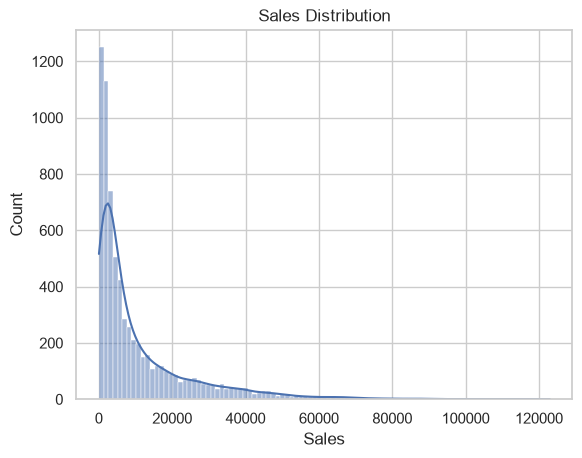

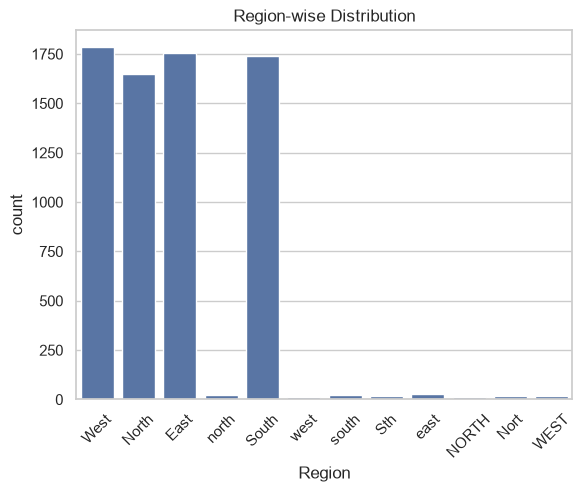

TC07 Passed: Visualizations generated successfully.


In [36]:
# Test Case 7: Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Sales distribution
sns.histplot(data=df_clean, x="Sales", kde=True)
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.show()

# Region-wise distribution
sns.countplot(data=df_clean, x="Region")
plt.title("Region-wise Distribution")
plt.xticks(rotation=45)
plt.show()

print("TC07 Passed: Visualizations generated successfully.")

In [37]:
# Test Case 8: Outlier Detection

for col in ["Sales", "Profit", "Age", "Income"]:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

print("TC08 Passed: Outlier detection completed successfully.")

Sales Outliers: 641
Profit Outliers: 644
Age Outliers: 17
Income Outliers: 245
TC08 Passed: Outlier detection completed successfully.


In [40]:
# Test Case 9: Feature Engineering

required_columns = [
    "Profit_Margin",
    "Delivery_Days",
    "Revenue_per_Customer"
]

for col in required_columns:
    assert col in df_clean.columns, f"{col} is missing!"

print("TC09 Passed: All engineered columns are available.")

TC09 Passed: All engineered columns are available.


In [39]:
# Feature Engineering

# Calculate Profit Margin
df_clean['Profit_Margin'] = np.where(
    df_clean['Sales'] != 0,
    (df_clean['Profit'] / df_clean['Sales']) * 100,
    0
)

# Calculate Delivery Days
df_clean['Delivery_Days'] = (
    df_clean['Delivery_Date'] - df_clean['Order_Date']
).dt.days

# Calculate Revenue per Customer
df_clean['Revenue_per_Customer'] = (
    df_clean.groupby('Customer_ID')['Sales'].transform('sum')
)

print("Feature engineering completed!")
print(df_clean[
    ['Profit_Margin', 'Delivery_Days', 'Revenue_per_Customer']
].head())

Feature engineering completed!
   Profit_Margin  Delivery_Days  Revenue_per_Customer
0      33.506128            6.0               5003.25
1      26.977932            4.0              74411.80
2      39.029546            8.0             103073.78
3      36.567360            4.0              29951.36
4      33.618106            7.0              21572.93


In [42]:
# Test Case 10: Cleaned Dataset Export

import os

output_file = "cleaned_retail_customer_sales_dataset_final.csv"

df_clean.to_csv(output_file, index=False)

assert os.path.exists(output_file), "File was not saved!"

print("TC10 Passed: Cleaned dataset exported successfully.")
print("File Name:", output_file)
print("File Location:", os.path.abspath(output_file))

TC10 Passed: Cleaned dataset exported successfully.
File Name: cleaned_retail_customer_sales_dataset_final.csv
File Location: c:\Users\hp\Desktop\ansh_dabas_2026M01410095\cleaned_retail_customer_sales_dataset_final.csv
